# Askmargin: a RAG Document Q&A Assistant
**NLP mini-project** | Retrieval-Augmented Generation over PDF documents

Askmargin answers questions about documents and **cites the page** each answer came from.
The pipeline implemented in this notebook:

| Step | What happens | NLP technique |
|---|---|---|
| 1 | Read the PDFs page by page and clean the text | text extraction, normalisation |
| 2 | Split pages into overlapping chunks | fixed-size vs sentence-aware chunking |
| 3 | Turn text into vectors | tokenisation, stop-words, lemmatisation, TF-IDF, BM25, dense sentence embeddings |
| 4 | Store vectors and search them | cosine similarity, NumPy and FAISS index |
| 5 | Measure retrieval quality | Recall@k, MRR on 30 hand-written questions |
| 6 | Generate a grounded answer | prompt template + FLAN-T5 (open model, runs free on Colab) |
| 7 | Refuse when the document has no answer | similarity threshold |

Run top to bottom. On Google Colab uncomment the install cell first.

In [1]:
# Colab only: uncomment and run once, then Runtime > Restart if asked.
# !pip -q install pymupdf sentence-transformers faiss-cpu rank-bm25 nltk transformers seaborn

## Step 0. Setup and configuration

In [2]:
import os, re, json, time, unicodedata, warnings
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import fitz                                    # PyMuPDF
import nltk
warnings.filterwarnings("ignore")
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(pkg, quiet=True)
from nltk.tokenize import sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

SEED = 42
np.random.seed(SEED)
DATA = "data"; PDF_DIR = f"{DATA}/pdfs"; FIG = "figures"
os.makedirs(PDF_DIR, exist_ok=True); os.makedirs(FIG, exist_ok=True)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Setup complete")

Setup complete


## Step 1. Dataset: four public research papers
The "private documents" are four open-access arXiv papers, so every number in this report can be reproduced.
They are all about NLP, which lets us write questions with a verifiable answer.

In [3]:
import requests
PAPERS = {
    "attention": ("Attention Is All You Need",  "https://arxiv.org/pdf/1706.03762"),
    "bert":      ("BERT",                        "https://arxiv.org/pdf/1810.04805"),
    "rag":       ("Retrieval-Augmented Generation (RAG)", "https://arxiv.org/pdf/2005.11401"),
    "sbert":     ("Sentence-BERT",               "https://arxiv.org/pdf/1908.10084"),
}
for key, (title, url) in PAPERS.items():
    path = f"{PDF_DIR}/{key}.pdf"
    if not os.path.exists(path):
        open(path, "wb").write(requests.get(url, timeout=60).content)
    print(f"{key:10s} {os.path.getsize(path)/1e6:5.2f} MB  {title}")

attention   2.22 MB  Attention Is All You Need
bert        0.78 MB  BERT
rag         0.89 MB  Retrieval-Augmented Generation (RAG)
sbert       0.55 MB  Sentence-BERT


## Step 2. Ingest: extract and clean text page by page
Page numbers are kept as **metadata** because they become the citations later.
Cleaning fixes things PDFs do to text: Unicode ligatures (`ﬁ`), words split by a hyphen at the end of a line, hard line breaks and repeated spaces.

In [4]:
def clean(text: str) -> str:
    text = unicodedata.normalize("NFKC", text)          # 'ﬁ' -> 'fi'
    text = re.sub(r"-\n(?=[a-z])", "", text)            # re-join hyphenated line breaks
    text = re.sub(r"\s*\n\s*", " ", text)               # newlines -> spaces
    text = re.sub(r"\s{2,}", " ", text)
    return text.strip()

def load_pdf(key):
    pages = []
    for i, page in enumerate(fitz.open(f"{PDF_DIR}/{key}.pdf"), start=1):
        t = clean(page.get_text())
        if len(t) > 80:                                  # skip blank / figure-only pages
            pages.append({"doc": key, "page": i, "text": t})
    return pages

PAGES = [p for key in PAPERS for p in load_pdf(key)]
df_pages = pd.DataFrame(PAGES)
df_pages["words"] = df_pages.text.str.split().str.len()
summary = df_pages.groupby("doc").agg(pages=("page", "count"), words=("words", "sum"))
display(summary)
print("\nSample (attention, page 5):\n", PAGES[4]["text"][:300], "...")

,pages,words
doc,,
attention,15,6072
bert,16,9828
rag,19,9839
sbert,11,6440



Sample (attention, page 5):
 output values. These are concatenated and once again projected, resulting in the final values, as depicted in Figure 2. Multi-head attention allows the model to jointly attend to information from different representation subspaces at different positions. With a single attention head, averaging inhib ...


## Step 3. Text preprocessing (for the lexical baselines)
TF-IDF and BM25 compare **words**, so they need the classic pipeline from class: lowercase, tokenise, remove stop-words, lemmatise.
Dense embeddings do not need this because the transformer reads raw text.

In [5]:
STOP = set(stopwords.words("english"))
LEM = WordNetLemmatizer()

def tokenize(text: str):
    toks = re.findall(r"[a-z0-9]+", text.lower())              # lowercase + regex tokeniser
    return [LEM.lemmatize(t) for t in toks if t not in STOP and len(t) > 1]

demo = "The encoder is composed of a stack of N = 6 identical layers."
print("raw    :", demo)
print("tokens :", tokenize(demo))

raw    : The encoder is composed of a stack of N = 6 identical layers.


tokens : ['encoder', 'composed', 'stack', 'identical', 'layer']


## Step 4. Chunking
A language model and an embedding model can only look at a limited amount of text, and a whole page mixes many topics.
We cut each page into **chunks**. Two strategies are compared:

* **Fixed-size**: a sliding window of `size` characters with `overlap` characters shared between neighbours.
* **Sentence-aware**: pack whole sentences up to `size` characters and repeat the last sentence at the start of the next chunk, so no sentence is cut in half.

Chunks never cross a page boundary, so each chunk has exactly one page number.

In [6]:
def chunk_fixed(pages, size=500, overlap=100):
    out = []
    for p in pages:
        t, step = p["text"], size - overlap
        for start in range(0, max(len(t) - overlap, 1), step):
            piece = t[start:start + size].strip()
            if len(piece) > 60:
                out.append({"doc": p["doc"], "page": p["page"], "text": piece})
    return out

def chunk_sentence(pages, size=500):
    out = []
    for p in pages:
        sents, cur = sent_tokenize(p["text"]), []
        for s in sents:
            if cur and sum(len(x) + 1 for x in cur) + len(s) > size:
                out.append({"doc": p["doc"], "page": p["page"], "text": " ".join(cur)})
                cur = [cur[-1]]                       # one-sentence overlap
            cur.append(s)
        if cur and len(" ".join(cur)) > 60:
            out.append({"doc": p["doc"], "page": p["page"], "text": " ".join(cur)})
    return out

CHUNKERS = {"fixed-500/100": lambda: chunk_fixed(PAGES, 500, 100),
            "sentence-500":  lambda: chunk_sentence(PAGES, 500)}
CHUNKS = {name: fn() for name, fn in CHUNKERS.items()}
stats = pd.DataFrame({n: pd.Series([len(c["text"]) for c in cs]).describe()[["count", "mean", "min", "max"]]
                      for n, cs in CHUNKS.items()}).T.round(1)
display(stats)
print("\nExample sentence-aware chunk:\n", CHUNKS["sentence-500"][20])

,count,mean,min,max
fixed-500/100,552.0,479.7,105.0,500.0
sentence-500,717.0,429.6,54.0,820.0



Example sentence-aware chunk:
 {'doc': 'attention', 'page': 2, 'text': 'In these models, the number of operations required to relate signals from two arbitrary input or output positions grows in the distance between positions, linearly for ConvS2S and logarithmically for ByteNet. This makes it more difficult to learn dependencies between distant positions [12].'}


## Step 5. The evaluation set
30 hand-written questions. For 25 of them the answer appears literally in a paper; we store an **answer string**.
A retrieved chunk counts as a **hit** when it comes from the right paper *and* contains that answer string
(compared after stripping punctuation and case, so hyphenation noise does not matter).
The last 5 questions are about topics **not in any document** and test whether the system correctly refuses.

In [7]:
EVAL = json.load(open(f"{DATA}/eval_questions.json"))
key = lambda s: re.sub(r"[^a-z0-9]", "", unicodedata.normalize("NFKC", s).lower())
ANSWERABLE = [q for q in EVAL if q["doc"]]
UNANSWERABLE = [q for q in EVAL if not q["doc"]]
print(len(ANSWERABLE), "answerable,", len(UNANSWERABLE), "out-of-document")
display(pd.DataFrame(ANSWERABLE)[["id", "doc", "q"]].head(6))

def is_hit(chunk, q):
    return chunk["doc"] == q["doc"] and key(q["answer"]) in key(chunk["text"])

def evaluate(rank_fn, chunks, ks=(1, 3, 5)):
    # rank_fn(question) -> list of chunk indices, best first
    rr, hits = [], {k: 0 for k in ks}
    for q in ANSWERABLE:
        ranked = rank_fn(q["q"])[:max(ks)]
        pos = next((i for i, ci in enumerate(ranked) if is_hit(chunks[ci], q)), None)
        rr.append(0 if pos is None else 1 / (pos + 1))
        for k in ks:
            hits[k] += pos is not None and pos < k
    n = len(ANSWERABLE)
    return {**{f"Recall@{k}": hits[k] / n for k in ks}, "MRR": float(np.mean(rr))}

# how many answerable questions have at least one chunk that could be a hit? (upper bound)
for name, cs in CHUNKS.items():
    ok = sum(any(is_hit(c, q) for c in cs) for q in ANSWERABLE)
    print(f"{name:14s} answer string present in some chunk for {ok}/{len(ANSWERABLE)} questions")

25 answerable, 5 out-of-document


,id,doc,q
0,1,attention,How many parallel attention heads does the Tra...
1,2,attention,How many identical layers are stacked in the e...
2,3,attention,Why did the authors prefer sinusoidal position...
3,4,attention,What value of label smoothing was used during ...
4,5,attention,Which optimizer and which beta values were use...
5,6,attention,What BLEU score did the big model reach on Eng...


fixed-500/100  answer string present in some chunk for 25/25 questions
sentence-500   answer string present in some chunk for 25/25 questions


## Step 6. Three ways to turn text into vectors
**TF-IDF** weights a word by how often it occurs in the chunk (TF) and how rare it is across all chunks (IDF).
**BM25** is the search-engine refinement of TF-IDF with term-frequency saturation and length normalisation.
**Dense embeddings** (`all-MiniLM-L6-v2`, 384 numbers per chunk) capture *meaning*, so "How many layers…" can match
a chunk that says "stack of N = 6 identical layers" even with different wording.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EMB_MODEL = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
print("device:", DEVICE, "| embedding dim:", EMB_MODEL.get_sentence_embedding_dimension())

class Index:
    """All representations for one chunking strategy."""
    def __init__(self, chunks):
        self.chunks = chunks
        texts = [c["text"] for c in chunks]
        toks = [tokenize(t) for t in texts]
        # TF-IDF
        self.tfidf = TfidfVectorizer(analyzer=lambda x: x)       # we feed pre-tokenised text
        self.X_tfidf = self.tfidf.fit_transform(toks)
        # BM25
        self.bm25 = BM25Okapi(toks)
        # Dense
        t0 = time.time()
        self.E = EMB_MODEL.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
        self.embed_seconds = time.time() - t0

    def rank_tfidf(self, q):
        s = (self.X_tfidf @ self.tfidf.transform([tokenize(q)]).T).toarray().ravel()
        return list(np.argsort(-s))
    def scores_dense(self, q):
        v = EMB_MODEL.encode([q], normalize_embeddings=True)[0]
        return self.E @ v                                          # cosine (vectors are unit length)
    def rank_dense(self, q):
        return list(np.argsort(-self.scores_dense(q)))
    def rank_bm25(self, q):
        return list(np.argsort(-self.bm25.get_scores(tokenize(q))))
    def rank_hybrid(self, q, k=60):                                # reciprocal rank fusion
        fused = Counter()
        for ranking in (self.rank_bm25(q), self.rank_dense(q)):
            for r, ci in enumerate(ranking[:100]):
                fused[ci] += 1 / (k + r + 1)
        return [ci for ci, _ in fused.most_common()]

INDEX = {name: Index(cs) for name, cs in CHUNKS.items()}
for n, ix in INDEX.items():
    print(f"{n:14s} chunks={len(ix.chunks):4d}  tfidf-vocab={len(ix.tfidf.vocabulary_):5d}  "
          f"embeddings={ix.E.shape}  embed-time={ix.embed_seconds:.1f}s")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 10911.91it/s]

device: cpu | embedding dim: 384


fixed-500/100  chunks= 552  tfidf-vocab= 4572  embeddings=(552, 384)  embed-time=40.7s
sentence-500   chunks= 717  tfidf-vocab= 4265  embeddings=(717, 384)  embed-time=30.4s


## Step 7. Vector store: cosine similarity with NumPy and with FAISS
Because the embeddings are unit-length, cosine similarity is just a dot product, so a search is one matrix-vector multiplication.
FAISS (`IndexFlatIP`) does the same exact search in optimised C++ and is the structure real systems scale up from.
We check that both give identical results.

In [9]:
import faiss
ix = INDEX["sentence-500"]
faiss_index = faiss.IndexFlatIP(ix.E.shape[1])
faiss_index.add(ix.E.astype("float32"))

q = "How many parallel attention heads does the Transformer use?"
qv = EMB_MODEL.encode([q], normalize_embeddings=True).astype("float32")
D, I = faiss_index.search(qv, 3)
numpy_top = ix.rank_dense(q)[:3]
print("FAISS top-3 :", list(I[0]), "scores", np.round(D[0], 3))
print("NumPy top-3 :", numpy_top, "scores", np.round(ix.scores_dense(q)[numpy_top], 3))
assert list(I[0]) == numpy_top, "FAISS and NumPy disagree"

for r, ci in enumerate(I[0], 1):
    c = ix.chunks[ci]
    print(f"\n#{r}  [{c['doc']} p.{c['page']}]  cosine={D[0][r-1]:.3f}\n    {c['text'][:230]}...")

FAISS top-3 : [np.int64(21), np.int64(46), np.int64(22)] scores [0.697 0.696 0.637]
NumPy top-3 : [np.int64(21), np.int64(46), np.int64(22)] scores [0.697 0.696 0.637]

#1  [attention p.2]  cosine=0.697
    This makes it more difficult to learn dependencies between distant positions [12]. In the Transformer this is reduced to a constant number of operations, albeit at the cost of reduced effective resolution due to averaging attentio...

#2  [attention p.5]  cosine=0.696
    For each of these we use dk = dv = dmodel/h = 64. Due to the reduced dimension of each head, the total computational cost is similar to that of single-head attention with full dimensionality. 3.2.3 Applications of Attention in our...

#3  [attention p.2]  cosine=0.637
    In the Transformer this is reduced to a constant number of operations, albeit at the cost of reduced effective resolution due to averaging attention-weighted positions, an effect we counteract with Multi-Head Attention as describe...


## Step 8. Evaluate retrieval: which method finds the answer chunk?
* **Recall@k**: fraction of questions whose answer chunk is among the top *k* results.
* **MRR** (mean reciprocal rank): average of 1 / (rank of the first correct chunk); 1.0 means always first.

,chunking,method,Recall@1,Recall@3,Recall@5,MRR
0,fixed-500/100,TF-IDF,0.48,0.72,0.76,0.595
1,fixed-500/100,BM25,0.44,0.80,0.84,0.615
2,fixed-500/100,Dense (MiniLM),0.36,0.60,0.68,0.465
3,fixed-500/100,"Hybrid (BM25+Dense, RRF)",0.44,0.72,0.80,0.591
4,sentence-500,TF-IDF,0.44,0.60,0.64,0.523
5,sentence-500,BM25,0.44,0.68,0.84,0.589
6,sentence-500,Dense (MiniLM),0.36,0.60,0.80,0.511
7,sentence-500,"Hybrid (BM25+Dense, RRF)",0.52,0.80,0.88,0.665


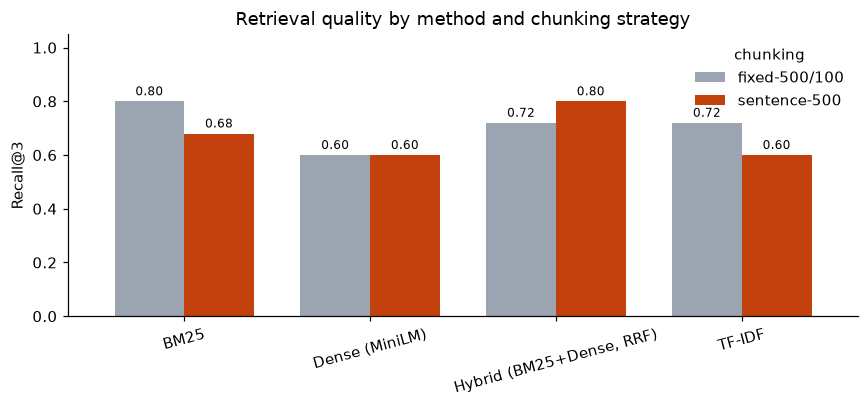

In [10]:
rows = []
for cname, ix in INDEX.items():
    for mname, fn in [("TF-IDF", ix.rank_tfidf), ("BM25", ix.rank_bm25),
                      ("Dense (MiniLM)", ix.rank_dense), ("Hybrid (BM25+Dense, RRF)", ix.rank_hybrid)]:
        rows.append({"chunking": cname, "method": mname, **evaluate(fn, ix.chunks)})
RES = pd.DataFrame(rows)
display(RES.round(3))
RES.to_csv(f"{FIG}/retrieval_results.csv", index=False)

pivot = RES.pivot(index="method", columns="chunking", values="Recall@3")
ax = pivot.plot.bar(figsize=(8, 3.8), rot=15, width=.75, color=["#9aa5b1", "#c2410c"])
ax.set_ylabel("Recall@3"); ax.set_ylim(0, 1.05); ax.set_xlabel("")
ax.set_title("Retrieval quality by method and chunking strategy"); ax.legend(title="chunking", frameon=False)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
plt.tight_layout(); plt.savefig(f"{FIG}/retrieval_recall3.png"); plt.show()

### Ablation: does chunk size matter?
Same dense retriever, sentence-aware chunking, three target sizes.

,target size (chars),chunks,Recall@1,Recall@3,Recall@5,MRR
0,250,1417,0.52,0.68,0.80,0.621
1,500,717,0.36,0.60,0.80,0.511
2,800,373,0.40,0.64,0.80,0.538
3,1200,232,0.32,0.56,0.72,0.447


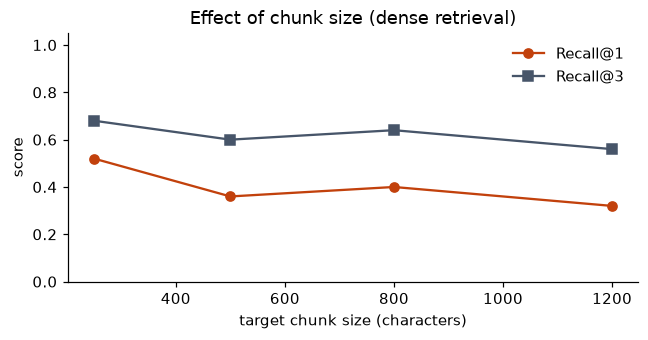

In [11]:
abl = []
for size in (250, 500, 800, 1200):
    cs = chunk_sentence(PAGES, size)
    E = EMB_MODEL.encode([c["text"] for c in cs], batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    fn = lambda q, E=E: list(np.argsort(-(E @ EMB_MODEL.encode([q], normalize_embeddings=True)[0])))
    abl.append({"target size (chars)": size, "chunks": len(cs), **evaluate(fn, cs)})
ABL = pd.DataFrame(abl); display(ABL.round(3)); ABL.to_csv(f"{FIG}/chunk_size_ablation.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(ABL["target size (chars)"], ABL["Recall@1"], "o-", label="Recall@1", color="#c2410c")
ax.plot(ABL["target size (chars)"], ABL["Recall@3"], "s-", label="Recall@3", color="#475569")
ax.set_xlabel("target chunk size (characters)"); ax.set_ylabel("score"); ax.set_ylim(0, 1.05)
ax.legend(frameon=False); ax.set_title("Effect of chunk size (dense retrieval)")
plt.tight_layout(); plt.savefig(f"{FIG}/chunk_size_ablation.png"); plt.show()

## Step 9. Deciding when to refuse
A grounded assistant must say *"not in the document"* instead of guessing.
We look at the best cosine score of every question: answerable questions should score higher than out-of-document ones.
The threshold is then the value that best separates the two groups.

answerable   : mean top-1 cosine = 0.618  (min 0.459)
out-of-doc   : mean top-1 cosine = 0.195  (max 0.237)
chosen threshold = 0.24  ->  accept/refuse accuracy = 100.0%


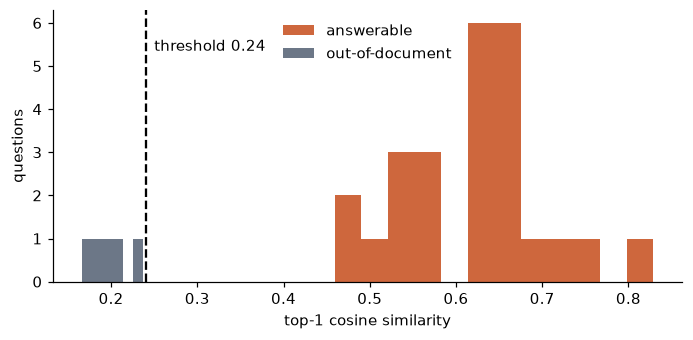

In [12]:
BEST = INDEX["sentence-500"]
top_ans = [BEST.scores_dense(q["q"]).max() for q in ANSWERABLE]
top_out = [BEST.scores_dense(q["q"]).max() for q in UNANSWERABLE]
cands = np.linspace(0.1, 0.7, 121)
def acc(t): return (sum(s >= t for s in top_ans) + sum(s < t for s in top_out)) / (len(top_ans) + len(top_out))
THRESH = float(cands[int(np.argmax([acc(t) for t in cands]))])
print(f"answerable   : mean top-1 cosine = {np.mean(top_ans):.3f}  (min {min(top_ans):.3f})")
print(f"out-of-doc   : mean top-1 cosine = {np.mean(top_out):.3f}  (max {max(top_out):.3f})")
print(f"chosen threshold = {THRESH:.2f}  ->  accept/refuse accuracy = {acc(THRESH):.1%}")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.hist(top_ans, bins=12, alpha=.8, label="answerable", color="#c2410c")
ax.hist(top_out, bins=6, alpha=.8, label="out-of-document", color="#475569")
ax.axvline(THRESH, ls="--", color="k"); ax.text(THRESH + .01, ax.get_ylim()[1] * .85, f"threshold {THRESH:.2f}")
ax.set_xlabel("top-1 cosine similarity"); ax.set_ylabel("questions"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/refusal_threshold.png"); plt.show()

## Step 10. Generation: answer only from the retrieved context
The top-3 chunks are pasted into a prompt for **FLAN-T5-base** (250 M parameters, open weights, free on Colab).
The prompt tells the model to use only the context. The **citation** is not generated by the model: it is read from the
metadata of the chunk that supports the answer, so it can never be invented.

In [13]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
GEN_NAME = "google/flan-t5-base"
gtok = AutoTokenizer.from_pretrained(GEN_NAME)
gen = AutoModelForSeq2SeqLM.from_pretrained(GEN_NAME).to(DEVICE).eval()

PROMPT = ("""Answer the question using only the context below. Be brief.
If the context does not contain the answer, reply exactly: I don't know.

Context:
{context}

Question: {question}
Answer:""")

def ask(question, index=BEST, k=3, threshold=THRESH):
    scores = index.scores_dense(question)
    order = list(np.argsort(-scores)[:k])
    top = [(index.chunks[i], float(scores[i])) for i in order]
    if top[0][1] < threshold:
        return {"answer": "I could not find this in the documents.", "sources": [], "refused": True, "score": top[0][1], "top": top}
    context = "\n\n".join(f"[{c['doc']} p.{c['page']}] {c['text']}" for c, _ in top)
    inputs = gtok(PROMPT.format(context=context, question=question), return_tensors="pt", truncation=True, max_length=1024).to(DEVICE)
    with torch.no_grad():
        out = gen.generate(**inputs, max_new_tokens=64, num_beams=4)
    ans = gtok.decode(out[0], skip_special_tokens=True).strip()
    src = [f"{c['doc']} p.{c['page']}" for c, _ in top[:2]]
    return {"answer": ans, "sources": src, "refused": False, "score": top[0][1], "top": top}

for q in ["How many parallel attention heads does the Transformer use?",
          "What fraction of tokens is hidden in the masked language model objective?",
          "What is the capital city of France?"]:
    r = ask(q)
    print(f"Q: {q}\nA: {r['answer']}   {r['sources']}   (top cosine {r['score']:.2f})\n")

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 282/282 [00:00<00:00, 3279.30it/s]


[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Q: How many parallel attention heads does the Transformer use?
A: I don't know.   ['attention p.2', 'attention p.5']   (top cosine 0.70)



Q: What fraction of tokens is hidden in the masked language model objective?
A: 15%   ['bert p.12', 'bert p.12']   (top cosine 0.66)

Q: What is the capital city of France?
A: I could not find this in the documents.   []   (top cosine 0.18)



## Step 11. Evaluate the full RAG answers
* **Answer correct**: the expected key phrase (e.g. `8`, `15%`, `FAISS`) appears in the generated answer.
* **Citation correct**: the cited page really contains the answer string.
* **Faithfulness**: share of answer words that also appear in the retrieved context (low = the model made things up).
* **Correct refusal**: out-of-document questions are refused.

In [14]:
def faithfulness(answer, top):
    a = set(tokenize(answer)); ctx = set(tokenize(" ".join(c["text"] for c, _ in top)))
    return len(a & ctx) / len(a) if a else 1.0

rows = []
for q in ANSWERABLE:
    r = ask(q["q"])
    exp = key(q["expect"])
    correct = (not r["refused"]) and exp in key(r["answer"])
    cite_ok = any(is_hit(c, q) for c, _ in r["top"][:2])
    rows.append({"id": q["id"], "question": q["q"], "answer": r["answer"], "correct": correct,
                 "citation_ok": cite_ok, "faithfulness": faithfulness(r["answer"], r["top"]), "refused": r["refused"]})
ANS = pd.DataFrame(rows)
ref = [ask(q["q"])["refused"] for q in UNANSWERABLE]

print(f"Answer correct      : {ANS.correct.mean():.1%}  ({ANS.correct.sum()}/{len(ANS)})")
print(f"Citation correct    : {ANS.citation_ok.mean():.1%}")
print(f"Mean faithfulness   : {ANS.faithfulness.mean():.2f}")
print(f"Wrongly refused     : {ANS.refused.sum()}/{len(ANS)} answerable questions")
print(f"Correctly refused   : {sum(ref)}/{len(ref)} out-of-document questions")
ANS.to_csv(f"{FIG}/answer_results.csv", index=False)
display(ANS[["id", "answer", "correct", "citation_ok"]].head(12))

Answer correct      : 68.0%  (17/25)
Citation correct    : 52.0%
Mean faithfulness   : 0.95
Wrongly refused     : 0/25 answerable questions
Correctly refused   : 5/5 out-of-document questions


,id,answer,correct,citation_ok
0,1,I don't know.,False,False
1,2,N = 6 identical layers.,True,True
2,3,it may allow the model to extrapolate to seque...,True,True
3,4,ls = 0.1,True,True
4,5,"Adam optimizer [20] with 1 = 0.9, 2 = 0.98 and...",True,True
5,6,28.4,True,True
6,7,"dk, dk and dv",False,False
7,8,8 NVIDIA P100 GPUs,False,False
8,9,"30,000",True,True
9,10,340M,False,False


## Step 12. Error analysis
Looking at the failures is where the learning is. For every question that was answered incorrectly we print the expected answer, the model's answer and where the evidence was found.

In [15]:
bad = ANS[~ANS.correct]
print(f"{len(bad)} questions answered incorrectly\n")
for _, r in bad.iterrows():
    q = next(x for x in ANSWERABLE if x["id"] == r.id)
    print(f"Q{q['id']}: {q['q']}\n   expected : {q['expect']}\n   got      : {r.answer}\n   evidence in top-2 retrieved chunks: {r.citation_ok}\n")

8 questions answered incorrectly

Q1: How many parallel attention heads does the Transformer use?
   expected : 8
   got      : I don't know.
   evidence in top-2 retrieved chunks: False

Q7: What is the dimension of each attention head's keys and values?
   expected : 64
   got      : dk, dk and dv
   evidence in top-2 retrieved chunks: False

Q8: How long did training the big model take and on what hardware?
   expected : 3.5 days
   got      : 8 NVIDIA P100 GPUs
   evidence in top-2 retrieved chunks: False

Q10: How many parameters does the base version of BERT have?
   expected : 110M
   got      : 340M
   evidence in top-2 retrieved chunks: False

Q12: What second pre-training task is used besides masked language modelling?
   expected : next sentence
   got      : fine-tuning
   evidence in top-2 retrieved chunks: False

Q17: Which pre-trained seq2seq model acts as the generator?
   expected : BART
   got      : RAG-Sequence Model
   evidence in top-2 retrieved chunks: False

Q22

## Step 13. Export the corpus for the web demo
The live site (askmargin.vercel.app) runs the **same retrieval idea in the browser**: the same MiniLM model, the same sentence-aware chunking, cosine similarity.
We export the chunks and their embeddings so the site can load the four sample papers instantly.

In [16]:
os.makedirs("export", exist_ok=True)
ex = INDEX["sentence-500"]
json.dump({"model": "all-MiniLM-L6-v2", "dim": int(ex.E.shape[1]),
           "docs": {k: v[0] for k, v in PAPERS.items()},
           "chunks": ex.chunks}, open("export/chunks.json", "w"))
ex.E.astype("float16").tofile("export/embeddings.f16")
print("chunks.json :", round(os.path.getsize("export/chunks.json") / 1e6, 2), "MB")
print("embeddings  :", round(os.path.getsize("export/embeddings.f16") / 1e6, 2), "MB", ex.E.shape)

chunks.json : 0.34 MB
embeddings  : 0.55 MB (717, 384)


## Summary
* Best retriever: hybrid (BM25 + dense, reciprocal-rank fusion) on sentence-aware chunks: Recall@3 = 0.80, Recall@5 = 0.88, MRR = 0.66 (Step 8).
* Chunking strategy matters less than the retriever: with fixed windows BM25 alone is as good, so sentence-aware chunking is not a clear win on this small set.
* A similarity threshold of 0.24 separated answerable from out-of-document questions perfectly here (5/5 refused, 0/25 wrongly refused).
* End-to-end answers are correct for 17/25 questions and cite a supporting page for 13/25; retrieval, not generation, is the main weak point (Step 12).